# 02 · Entrenamiento y evaluación de modelos

**Proyecto 12 — Detector de anomalías en transferencias del SPI** · Luz Mereles · Sol Nuñez

Este notebook entrena, evalúa y exporta el modelo que usa la API. Todo el código está aquí; lo único que se importa
del proyecto es `features.py`, para que las 14 variables se calculen **exactamente igual** al entrenar y en la API.

| Etapa | Qué se hace | Conjunto |
|---|---|---|
| **1. Primera prueba** | Regresión logística (*baseline*) y XGBoost ponderado, con su configuración base y **sin ajustes** | Validación (mar – abr 2026) |
| **2. Ajuste** | Solo XGBoost ponderado: **hiperparámetros** (Optuna) y **umbral de decisión** | Entrenamiento + validación |
| **3. Evaluación final** | Solo el XGBoost ponderado ajustado, **una única vez** | Prueba (may – jun 2026) |

El conjunto de prueba no se usa para elegir nada: se mira recién al final. Al terminar se exportan
`models/modelo_xgb.json` y `models/metadata.json` (los lee la API), y los gráficos y tablas a `reports/`.

**Cómo ejecutarlo en Google Colab:** subí la carpeta `detector-sip` a *Mi unidad* de Google Drive, abrí este
archivo desde Drive (*clic derecho → Abrir con → Google Colaboratory*) y elegí *Entorno de ejecución → Ejecutar todas*.
Tarda entre 10 y 25 minutos (la búsqueda de hiperparámetros es la parte más larga). Los resultados quedan guardados
en la misma carpeta de Drive.

**En la PC (sin Colab):** instalá `requirements.txt` y abrí el notebook con Jupyter o VS Code desde la carpeta
`notebooks/`; la primera celda detecta que no está en Colab y usa la carpeta del proyecto.

In [1]:
# ---------- Preparación del entorno: Google Colab (con Drive) o local ----------
import os, sys, subprocess
from pathlib import Path

# Carpeta del proyecto en tu Google Drive. Si la guardaste en otro lugar, cambiá esta ruta.
CARPETA_EN_DRIVE = "/content/drive/MyDrive/detector-sip"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path(CARPETA_EN_DRIVE)
    # lo único que no trae Colab (optuna); el resto ya está instalado
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(RAIZ / "requirements-colab.txt")], check=True)
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

CSV = RAIZ / "data" / "transacciones_spi.csv.gz"
assert CSV.exists(), f"No encuentro {CSV}. Revisá CARPETA_EN_DRIVE o ejecutá generar_datos.py"
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))   # para importar features.py (el mismo que usa la API)
print("Proyecto:", RAIZ)

Proyecto: /home/claude/detector-sip


In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Paleta validada: azul = legítima, naranja = fraude; colores de estado solo para decisiones
AZUL, NARANJA = "#2a78d6", "#eb6834"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
ESTADO = {"APROBAR": "#0ca30c", "REVISAR": "#fab219", "BLOQUEAR": "#d03b3b"}
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
CMAP_AZUL = matplotlib.colors.LinearSegmentedColormap.from_list("azul", ["#f4f8fd", "#86b6ef", "#256abf", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.dpi": 170, "figure.dpi": 90,
    "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRILLA,
    "grid.linewidth": 0.6, "legend.frameon": False, "text.color": TINTA,
})
NOMBRE_TIPO = {"toma_de_cuenta": "Toma de cuenta", "rafaga_de_transferencias": "Ráfaga de transferencias",
               "cuenta_mula": "Cuenta mula", "camuflado": "Camuflado", "ninguno": "Legítima"}
ORDEN_TIPOS = ["toma_de_cuenta", "rafaga_de_transferencias", "cuenta_mula", "camuflado"]


def gs(v):
    return f"{v:,.0f}".replace(",", ".")


def guardar(fig, nombre):
    """Guarda la figura en la carpeta de salida y la muestra en el notebook."""
    fig.tight_layout()
    fig.savefig(SALIDA / nombre, bbox_inches="tight")
    plt.show()

import json, time
from datetime import datetime, timezone
import optuna
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from features import FEATURES, construir_features, leer_dataset, particion

SALIDA = RAIZ / "reports" / "figures"      # gráficos
REPORTES = RAIZ / "reports"                # tablas y resultados
MODELOS = RAIZ / "models"                  # modelo final para la API
for carpeta in (SALIDA, REPORTES, MODELOS):
    carpeta.mkdir(parents=True, exist_ok=True)
print("xgboost", xgb.__version__, "· optuna", optuna.__version__)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


xgboost 3.4.1 · optuna 5.0.0


## Parámetros ajustables

Todo lo que se puede ajustar a mano está en esta celda. Cambiá un valor y ejecutá de nuevo **todo** el notebook
(*Entorno de ejecución → Ejecutar todas*): se vuelven a exportar el modelo, el `metadata.json` (con los umbrales) y los
gráficos, y la API los toma sin cambiar código. Las features y la partición temporal no se tocan aquí: están en
`features.py`, que comparten el notebook y la API.

In [3]:
SEED = 42                       # semilla: mismos datos + misma semilla = mismos resultados

# Etapa 1 — configuración base (sin ajustar)
UMBRAL_DEFECTO = 0.5            # umbral de clasificación antes de ajustar
XGB_BASE = dict(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9)

# Etapa 2 — ajuste del XGBoost ponderado
N_PRUEBAS = 40                  # combinaciones de hiperparámetros que prueba Optuna (más = mejor búsqueda, más tiempo)
PRECISIONES_BLOQUEO = (0.90, 0.80, 0.70, 0.60)  # BLOQUEAR: primera precisión alcanzable en validación
PRECISION_REVISION = 0.20       # REVISAR: de todo lo que se frena (revisión + bloqueo), al menos este % es fraude...
MAX_TASA_REVISION = 0.003       # ...sin frenar más de este % del flujo (capacidad de los analistas)

## 1. Datos, features y partición temporal

Las 14 features (fórmulas en `features.py`) se calculan con información que el banco emisor conoce al autorizar la
transferencia. Identificadores, bancos, `dispositivo_id`, `timestamp` sin transformar, `es_fraude` y `tipo_fraude`
**no** entran al modelo. La partición es **temporal**: se entrena con el pasado y se evalúa con el futuro, como en
producción.

In [4]:
df = leer_dataset(CSV)
X = construir_features(df)
y = df["es_fraude"].to_numpy()
parte = particion(df["timestamp"]).to_numpy()
tr, va, te = parte == "entrenamiento", parte == "validacion", parte == "prueba"
Xtr, ytr, Xva, yva, Xte, yte = X[tr], y[tr], X[va], y[va], X[te], y[te]

FEATURES_DEFINIDAS = ["log_monto", "log_ratio_monto_promedio", "sin_historial", "hora", "es_nocturna",
                      "dia_semana", "es_fin_de_semana", "es_fin_de_mes", "log_antiguedad_origen",
                      "n_tx_1h", "n_tx_24h", "destinatario_nuevo", "dispositivo_nuevo", "ciudad_distinta"]
assert FEATURES == FEATURES_DEFINIDAS and list(X.columns) == FEATURES_DEFINIDAS
assert "tipo_fraude" not in X.columns and "es_fraude" not in X.columns

resumen_particion = pd.DataFrame({
    "período": ["jul 2025 – feb 2026", "mar – abr 2026", "may – jun 2026"],
    "transferencias": [tr.sum(), va.sum(), te.sum()],
    "fraudes": [ytr.sum(), yva.sum(), yte.sum()],
}, index=["entrenamiento", "validación", "prueba"])
resumen_particion["% fraude"] = (resumen_particion["fraudes"] / resumen_particion["transferencias"] * 100).round(4)
resumen_particion

,período,transferencias,fraudes,% fraude
entrenamiento,jul 2025 – feb 2026,1136689,955,0.084
validación,mar – abr 2026,275444,157,0.057
prueba,may – jun 2026,277778,250,0.090


### Pesos de clase (calculados solo con entrenamiento)

- **XGBoost ponderado:** `scale_pos_weight` = legítimas / fraudes **de entrenamiento**.
- **Regresión logística:** `class_weight="balanced"` → peso de cada clase = n / (2 · n_clase), también con entrenamiento.

Así cada fraude "pesa" en la pérdida tanto como cientos de transferencias legítimas y el modelo no aprende a decir
siempre "legítima".

In [5]:
ratio = (ytr == 0).sum() / (ytr == 1).sum()
peso_fraude_lr = len(ytr) / (2 * ytr.sum())
peso_legitima_lr = len(ytr) / (2 * (ytr == 0).sum())
print(f"Legítimas / fraudes en entrenamiento = {ratio:,.1f}  ->  scale_pos_weight de XGBoost")
print(f"Regresión logística balanceada: peso fraude = {peso_fraude_lr:,.1f} · peso legítima = {peso_legitima_lr:.3f}")

Legítimas / fraudes en entrenamiento = 1,189.3  ->  scale_pos_weight de XGBoost
Regresión logística balanceada: peso fraude = 595.1 · peso legítima = 0.500


### Funciones de evaluación

Para cada modelo y conjunto se calculan `average_precision_score`, `roc_auc_score`, `f1_score`, `precision_score`,
`recall_score`, `confusion_matrix` y `classification_report`. La **average precision (PR-AUC)** y la **ROC-AUC** no
dependen del umbral; F1, precisión, recall y la matriz de confusión sí.

In [6]:
def metricas(y_real, prob, umbral):
    pred = (prob >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {"umbral": round(float(umbral), 4),
            "average_precision": round(float(average_precision_score(y_real, prob)), 4),
            "roc_auc": round(float(roc_auc_score(y_real, prob)), 4),
            "f1": round(float(f1_score(y_real, pred, zero_division=0)), 4),
            "precision": round(float(precision_score(y_real, pred, zero_division=0)), 4),
            "recall": round(float(recall_score(y_real, pred, zero_division=0)), 4),
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}


REPORTES_TXT = []   # classification_report de cada evaluación (se exportan al final)
RESULTADOS = []     # una fila por (etapa, modelo, conjunto)


def evaluar(etapa, nombre, conjunto, y_real, prob, umbral):
    m = metricas(y_real, prob, umbral)
    RESULTADOS.append({"etapa": etapa, "modelo": nombre, "conjunto": conjunto, **m})
    rep = classification_report(y_real, (prob >= umbral).astype(int), labels=[0, 1],
                                target_names=["legítima", "fraude"], digits=4, zero_division=0)
    cm = f"[[TN={m['tn']:,}  FP={m['fp']:,}]\n [FN={m['fn']:,}  TP={m['tp']:,}]]"
    REPORTES_TXT.append(f"{'=' * 72}\n{etapa} · {nombre} · {conjunto} · umbral {umbral:.4f}\n{rep}confusion_matrix\n{cm}\n")
    print(f"{nombre} — {conjunto} (umbral {umbral:.4f})")
    print(f"  average_precision={m['average_precision']}  roc_auc={m['roc_auc']}  f1={m['f1']}  "
          f"precision={m['precision']}  recall={m['recall']}")
    print(rep)
    print("confusion_matrix:\n" + cm)
    return m


def xgb_base(**kw):
    """XGBoost con la configuración base del proyecto (la que se usa sin ajustar)."""
    params = dict(**XGB_BASE, tree_method="hist", eval_metric="aucpr", random_state=SEED, n_jobs=-1)
    params.update(kw)
    return xgb.XGBClassifier(**params)


def shap_medio(modelo, Xs):
    """Importancia global: media del |valor SHAP| (TreeSHAP nativo de XGBoost)."""
    c = modelo.get_booster().predict(xgb.DMatrix(Xs, feature_names=FEATURES), pred_contribs=True)[:, :-1]
    return pd.Series(np.abs(c).mean(0), index=FEATURES)

## 2. Etapa 1 — Primera prueba en validación (sin ajustes)

Los dos modelos se entrenan con el conjunto de entrenamiento y se evalúan en **validación**, con su configuración base
y el **umbral por defecto de 0,5** (no se ajusta nada en esta etapa). Como el umbral no está ajustado, la comparación
principal se hace con la **average precision**, que no depende del umbral; F1, precisión y recall a 0,5 muestran
cómo se comporta cada modelo "tal cual".

| Modelo | Configuración |
|---|---|
| Regresión logística (*baseline*) | `StandardScaler` + `LogisticRegression(class_weight="balanced")`; el escalado se ajusta solo con entrenamiento |
| XGBoost ponderado | XGBoost base con `scale_pos_weight` = ratio de entrenamiento (el desbalance se compensa con pesos, sin crear fraudes sintéticos) |

XGBoost base: 300 árboles, profundidad 5, learning rate 0,1, `subsample` y `colsample_bytree` 0,9.

In [7]:
prob_val = {}
importancias = {}

t0 = time.perf_counter()
lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)).fit(Xtr, ytr)
print(f"Entrenada en {time.perf_counter() - t0:.1f} s\n")
prob_val["Regresión logística"] = lr.predict_proba(Xva)[:, 1]
evaluar("1 · sin ajustes", "Regresión logística", "validación", yva, prob_val["Regresión logística"], UMBRAL_DEFECTO)
importancias["Regresión logística"] = pd.Series(lr[-1].coef_[0], index=FEATURES)

Entrenada en 1.8 s



Regresión logística — validación (umbral 0.5000)
  average_precision=0.1187  roc_auc=0.9614  f1=0.0249  precision=0.0126  recall=0.8726
              precision    recall  f1-score   support

    legítima     0.9999    0.9610    0.9801    275287
      fraude     0.0126    0.8726    0.0249       157

    accuracy                         0.9610    275444
   macro avg     0.5063    0.9168    0.5025    275444
weighted avg     0.9994    0.9610    0.9795    275444

confusion_matrix:
[[TN=264,558  FP=10,729]
 [FN=20  TP=137]]


In [8]:
t0 = time.perf_counter()
xgb_pond = xgb_base(scale_pos_weight=ratio).fit(Xtr, ytr)
print(f"Entrenada en {time.perf_counter() - t0:.1f} s\n")
prob_val["XGBoost ponderado"] = xgb_pond.predict_proba(Xva)[:, 1]
evaluar("1 · sin ajustes", "XGBoost ponderado", "validación", yva, prob_val["XGBoost ponderado"], UMBRAL_DEFECTO)
importancias["XGBoost ponderado"] = shap_medio(xgb_pond, Xva)

Entrenada en 11.7 s



XGBoost ponderado — validación (umbral 0.5000)
  average_precision=0.5353  roc_auc=0.9726  f1=0.2166  precision=0.1262  recall=0.7643
              precision    recall  f1-score   support

    legítima     0.9999    0.9970    0.9984    275287
      fraude     0.1262    0.7643    0.2166       157

    accuracy                         0.9968    275444
   macro avg     0.5630    0.8807    0.6075    275444
weighted avg     0.9994    0.9968    0.9980    275444

confusion_matrix:
[[TN=274,456  FP=831]
 [FN=37  TP=120]]


### Comparación de la etapa 1

,average_precision,roc_auc,f1,precision,recall,tp,fp,fn,tn
modelo,,,,,,,,,
Regresión logística,0.1187,0.9614,0.0249,0.0126,0.8726,137,10729,20,264558
XGBoost ponderado,0.5353,0.9726,0.2166,0.1262,0.7643,120,831,37,274456


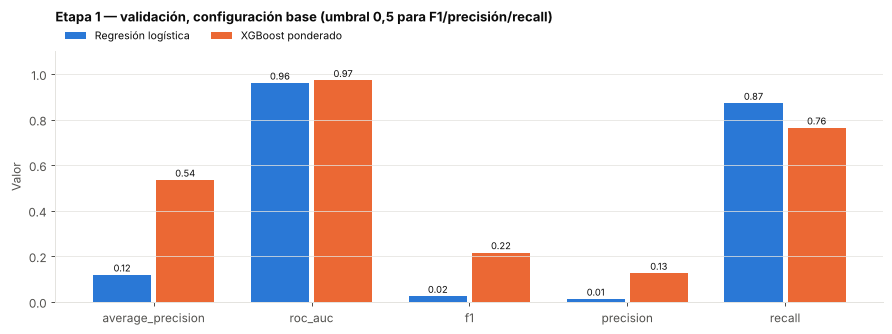

In [9]:
etapa1 = pd.DataFrame(RESULTADOS).set_index("modelo")[
    ["average_precision", "roc_auc", "f1", "precision", "recall", "tp", "fp", "fn", "tn"]]
display(etapa1)
MODELOS_E1 = list(prob_val)
COLOR = dict(zip(MODELOS_E1 + ["XGBoost ponderado ajustado"], SERIES))

fig, ax = plt.subplots(figsize=(10, 3.8))
nombres_m = ["average_precision", "roc_auc", "f1", "precision", "recall"]
x = np.arange(len(nombres_m))
for i, nombre in enumerate(MODELOS_E1):
    vals = etapa1.loc[nombre, nombres_m].to_numpy(dtype=float)
    ancho = 0.8 / len(MODELOS_E1)
    pos = x + (i - (len(MODELOS_E1) - 1) / 2) * ancho
    ax.bar(pos, vals, ancho * 0.92, color=COLOR[nombre], label=nombre)
    for xi, v in zip(pos, vals):
        ax.text(xi, v + 0.015, f"{v:.2f}", ha="center", fontsize=7.5)
ax.set_xticks(x, nombres_m)
ax.set(ylim=(0, 1.1), ylabel="Valor")
ax.set_title("Etapa 1 — validación, configuración base (umbral 0,5 para F1/precisión/recall)", loc="left", pad=24)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=len(MODELOS_E1), fontsize=8.5)
ax.grid(axis="x", visible=False)
guardar(fig, "01_etapa1_metricas_validacion.png")

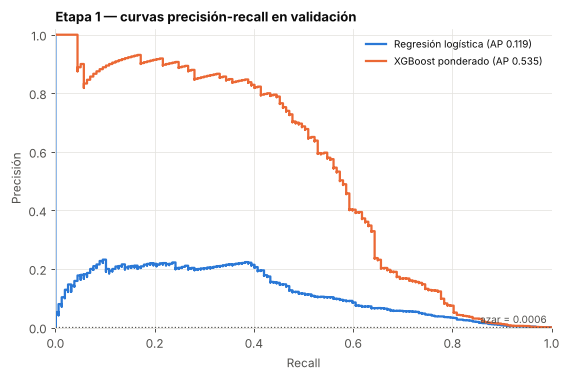

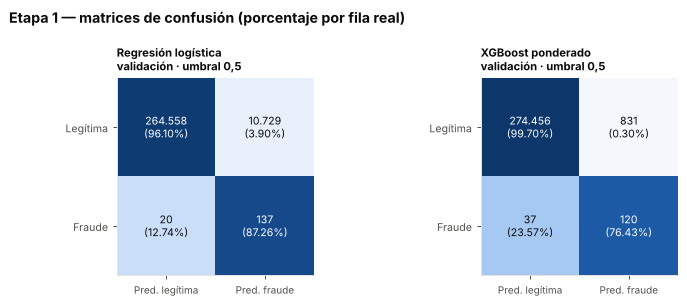

In [10]:
fig, ax = plt.subplots(figsize=(6.4, 4.3))
for nombre in MODELOS_E1:
    p, r, _ = precision_recall_curve(yva, prob_val[nombre])
    ax.step(r, p, where="post", color=COLOR[nombre], lw=1.8,
            label=f"{nombre} (AP {average_precision_score(yva, prob_val[nombre]):.3f})")
ax.axhline(yva.mean(), color=TINTA_2, ls=":", lw=1)
ax.text(0.99, yva.mean() + 0.015, f"azar = {yva.mean():.4f}", ha="right", fontsize=8, color=TINTA_2)
ax.set(xlabel="Recall", ylabel="Precisión", xlim=(0, 1), ylim=(0, 1.02),
       title="Etapa 1 — curvas precisión-recall en validación")
ax.legend(loc="upper right", fontsize=8)
guardar(fig, "02_etapa1_curvas_pr_validacion.png")

fig, axs = plt.subplots(1, len(MODELOS_E1), figsize=(4.2 * len(MODELOS_E1), 3.4))
for ax, nombre in zip(axs, MODELOS_E1):
    f = etapa1.loc[nombre]
    cm = np.array([[f["tn"], f["fp"]], [f["fn"], f["tp"]]])
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap=CMAP_AZUL, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{gs(cm[i, j])}\n({pct[i, j]:.2%})", ha="center", va="center", fontsize=8.5,
                    color="white" if pct[i, j] > 0.55 else TINTA)
    ax.set_xticks([0, 1], ["Pred. legítima", "Pred. fraude"], fontsize=8)
    ax.set_yticks([0, 1], ["Legítima", "Fraude"], fontsize=8.5)
    ax.grid(False)
    ax.set_title(f"{nombre}\nvalidación · umbral 0,5", fontsize=9)
fig.suptitle("Etapa 1 — matrices de confusión (porcentaje por fila real)", x=0.01, ha="left", fontweight="bold")
guardar(fig, "03_etapa1_matrices_validacion.png")

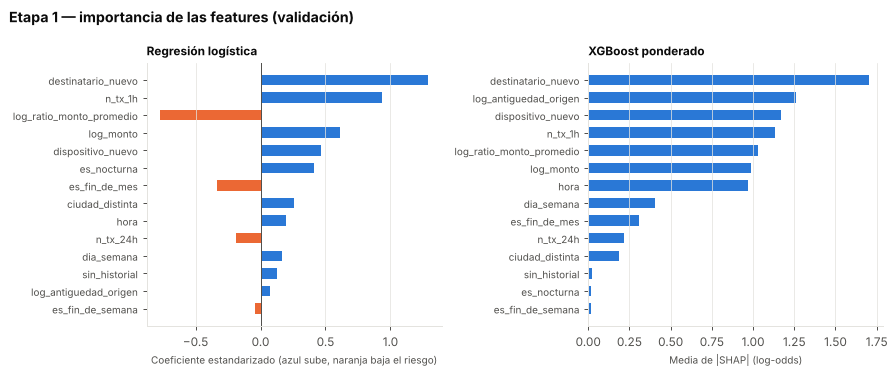

In [11]:
fig, axs = plt.subplots(1, len(MODELOS_E1), figsize=(5 * len(MODELOS_E1), 4.2))
for ax, nombre in zip(axs, MODELOS_E1):
    s = importancias[nombre].sort_values(key=np.abs)
    es_lr = nombre == "Regresión logística"
    ax.barh(s.index, s.values, height=0.6, color=[AZUL if (v >= 0 or not es_lr) else NARANJA for v in s.values])
    if es_lr:
        ax.axvline(0, color=TINTA_2, lw=0.8)
    ax.set_title(nombre, fontsize=9.5)
    ax.set_xlabel("Coeficiente estandarizado (azul sube, naranja baja el riesgo)" if es_lr
                  else "Media de |SHAP| (log-odds)", fontsize=8)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)
fig.suptitle("Etapa 1 — importancia de las features (validación)", x=0.01, ha="left", fontweight="bold")
guardar(fig, "04_etapa1_importancia_por_modelo.png")

**Lectura de la etapa 1.** La regresión logística es el *baseline*: es lineal, no puede combinar señales
("destinatario nuevo **y** varias transferencias en la última hora") y, con pesos balanceados y umbral 0,5, marca
muchísimas transferencias legítimas. El XGBoost ponderado combina señales y no altera los datos (compensa el
desbalance con pesos): es el modelo que se ajusta en la etapa 2. Su umbral de 0,5 todavía no está calibrado para este problema, por eso también se
ajusta.

## 3. Etapa 2 — Ajuste del XGBoost ponderado

### 3.1 Hiperparámetros (Optuna)

Optuna (muestreador TPE, semilla 42) prueba `N_PRUEBAS` combinaciones (40 por defecto). Cada una se entrena con **entrenamiento** y se mide
con la **average precision en validación**. Validación también se usa para el *early stopping*, que corta el
entrenamiento cuando 50 árboles seguidos no mejoran. El conjunto de prueba no interviene.

| Hiperparámetro | Rango | Justificación |
|---|---|---|
| `max_depth` | 3 – 8 | cuántas señales combina cada árbol; con ~1.000 fraudes, árboles muy profundos memorizan |
| `learning_rate` | 0,02 – 0,3 (log) | aporte de cada árbol: más bajo generaliza mejor pero necesita más árboles |
| `min_child_weight` | 1 – 30 (log) | peso mínimo por hoja: evita reglas sostenidas por 1 o 2 fraudes |
| `subsample` | 0,6 – 1,0 | fracción de transferencias por árbol: reduce la varianza |
| `colsample_bytree` | 0,5 – 1,0 | fracción de features por árbol: evita depender de una sola señal |
| `reg_lambda` | 0,001 – 20 (log) | regularización L2 de los valores de las hojas |
| `gamma` | 0 – 5 | ganancia mínima para dividir un nodo (poda) |
| `scale_pos_weight` | 2 % – 100 % del ratio (log) | el ratio completo infla las probabilidades; se busca el peso que mejor **ordena** |
| `n_estimators` | hasta 1.000 | lo fija el *early stopping* |

Se maximiza la **average precision** porque resume toda la curva precisión-recall sin depender del umbral, que se
ajusta después.

In [12]:
def objetivo(trial):
    params = {
        "n_estimators": 1000, "early_stopping_rounds": 50,
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 30, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 20, log=True),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "scale_pos_weight": ratio * trial.suggest_float("factor_peso", 0.02, 1.0, log=True),
    }
    m = xgb_base(**params).fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    trial.set_user_attr("n_estimators", int(m.best_iteration) + 1)
    return average_precision_score(yva, m.predict_proba(Xva)[:, 1])


optuna.logging.set_verbosity(optuna.logging.WARNING)
t0 = time.perf_counter()
estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
estudio.optimize(objetivo, n_trials=N_PRUEBAS, show_progress_bar=False)
print(f"{N_PRUEBAS} pruebas en {time.perf_counter() - t0:.0f} s · mejor average precision (validación): {estudio.best_value:.4f}")

historial = pd.DataFrame([{"prueba": t.number, "average_precision_val": round(t.value, 4),
                           **{k: round(v, 4) if isinstance(v, float) else v for k, v in t.params.items() if k != "factor_peso"},
                           "scale_pos_weight": round(ratio * t.params["factor_peso"], 2),
                           "n_estimators": t.user_attrs["n_estimators"]} for t in estudio.trials])
mejores = {k: v for k, v in estudio.best_params.items() if k != "factor_peso"}
mejores["scale_pos_weight"] = ratio * estudio.best_params["factor_peso"]
mejores["n_estimators"] = estudio.best_trial.user_attrs["n_estimators"]
display(historial.sort_values("average_precision_val", ascending=False).head(10))
print("Mejores hiperparámetros:", {k: round(v, 4) if isinstance(v, float) else v for k, v in mejores.items()})

40 pruebas en 377 s · mejor average precision (validación): 0.6323


,prueba,average_precision_val,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda,gamma,scale_pos_weight,n_estimators
39,39,0.6323,3,0.2005,8.7268,0.8433,0.9202,0.0048,3.5082,40.47,64
20,20,0.6267,4,0.1501,26.0025,0.8587,0.9711,0.0010,3.0250,39.79,54
32,32,0.6258,4,0.1653,9.1831,0.8398,0.9397,0.0028,3.6952,27.01,41
30,30,0.6227,5,0.2049,12.7783,0.8412,0.9416,0.0040,3.4599,26.90,26
35,35,0.6222,3,0.2265,14.2158,0.8489,0.9256,0.0028,3.2454,35.14,57
18,18,0.6208,3,0.0919,1.9374,0.8399,0.8465,0.0058,2.2737,25.66,111
9,9,0.6204,3,0.1820,11.0691,0.8916,0.8856,0.0021,1.7923,37.42,54
24,24,0.6202,4,0.1617,10.4007,0.8758,0.9413,0.0099,2.3094,24.45,42
33,33,0.6190,4,0.1541,7.8333,0.8301,0.9575,0.0027,3.5070,31.72,47
29,29,0.6188,3,0.1022,2.8615,0.8636,0.8520,0.0014,2.4793,35.89,119


Mejores hiperparámetros: {'max_depth': 3, 'learning_rate': 0.2005, 'min_child_weight': 8.7268, 'subsample': 0.8433, 'colsample_bytree': 0.9202, 'reg_lambda': 0.0048, 'gamma': 3.5082, 'scale_pos_weight': np.float64(40.4667), 'n_estimators': 64}


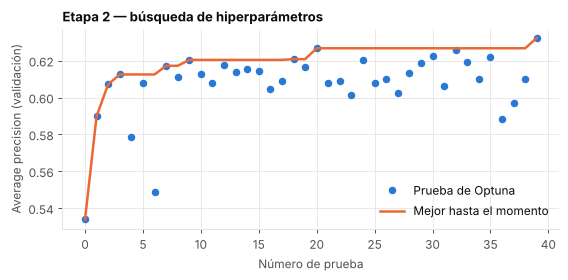

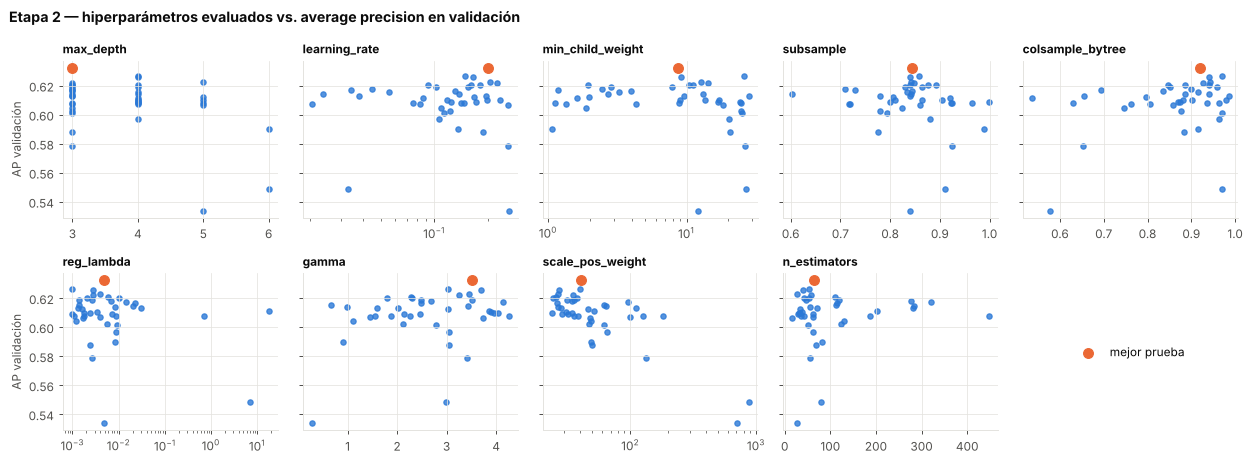

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(historial["prueba"], historial["average_precision_val"], "o", color=AZUL, ms=5, label="Prueba de Optuna")
ax.plot(historial["prueba"], historial["average_precision_val"].cummax(), color=NARANJA, lw=2, label="Mejor hasta el momento")
ax.set(xlabel="Número de prueba", ylabel="Average precision (validación)", title="Etapa 2 — búsqueda de hiperparámetros")
ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
ax.legend(loc="lower right")
guardar(fig, "05_etapa2_optuna_historial.png")

params_graf = ["max_depth", "learning_rate", "min_child_weight", "subsample", "colsample_bytree",
               "reg_lambda", "gamma", "scale_pos_weight", "n_estimators"]
fig, axs = plt.subplots(2, 5, figsize=(14, 5.2), sharey=True)
axs = axs.ravel()
mejor = historial["average_precision_val"].idxmax()
for ax, p in zip(axs, params_graf):
    ax.scatter(historial[p], historial["average_precision_val"], s=18, color=AZUL, alpha=0.8)
    ax.scatter(historial.loc[mejor, p], historial.loc[mejor, "average_precision_val"], s=60, color=NARANJA,
               zorder=3, label="mejor prueba")
    if p in ("learning_rate", "min_child_weight", "reg_lambda", "scale_pos_weight"):
        ax.set_xscale("log")
        ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.set_title(p, fontsize=9.5)
axs[0].set_ylabel("AP validación")
axs[5].set_ylabel("AP validación")
axs[-1].axis("off")
axs[-1].legend(*axs[0].get_legend_handles_labels(), loc="center")
fig.suptitle("Etapa 2 — hiperparámetros evaluados vs. average precision en validación", x=0.01, ha="left", fontweight="bold")
guardar(fig, "06_etapa2_optuna_hiperparametros.png")

Con los mejores hiperparámetros se entrena el modelo final **solo con entrenamiento**, usando la cantidad de árboles
que encontró el *early stopping*.

In [14]:
t0 = time.perf_counter()
modelo = xgb_base(**mejores).fit(Xtr, ytr)
print(f"Modelo final entrenado en {time.perf_counter() - t0:.1f} s")
p_tr, p_va = modelo.predict_proba(Xtr)[:, 1], modelo.predict_proba(Xva)[:, 1]

Modelo final entrenado en 2.4 s


### 3.2 Umbral de decisión

El modelo devuelve una probabilidad; el **umbral** decide a partir de cuánto una transferencia se considera fraude.
Se elige en **validación**, con dos criterios:

1. **Umbral de clasificación (fraude / legítima)**: el que **maximiza F1** en validación. F1 equilibra precisión
   (no molestar a clientes legítimos) y recall (no dejar pasar fraudes). Con él se reportan F1, precisión, recall y
   la matriz de confusión.
2. **Política de la API en 3 niveles**, con umbrales también elegidos en validación:
   - **BLOQUEAR** si el score ≥ el primer umbral con **precisión ≥ 90 %** (si no se alcanza, se prueba 80 %, 70 % y
     60 %): bloquear a un cliente legítimo es caro.
   - **REVISAR** si el score ≥ el umbral más bajo con el que, **de todo lo que se frena (revisión + bloqueo), al menos
     el 20 % es fraude** (como mucho 4 legítimas por cada fraude), sin frenar más del **0,3 %** de las transferencias,
     que es la capacidad supuesta de los analistas. No se usa una meta de recall alto (por ejemplo 90 %): el camuflado
     imita el comportamiento normal y, para atraparlo, habría que mandar a revisión una parte enorme del flujo.
   - **APROBAR** en otro caso.

Umbral de clasificación (máximo F1 en validación): 0.8485
Política de la API: {'umbral_bloqueo': 0.964326, 'umbral_revision': 0.452996, 'precision_objetivo_bloqueo': 0.9, 'precision_minima_revision': 0.2, 'max_tasa_revision': 0.003}


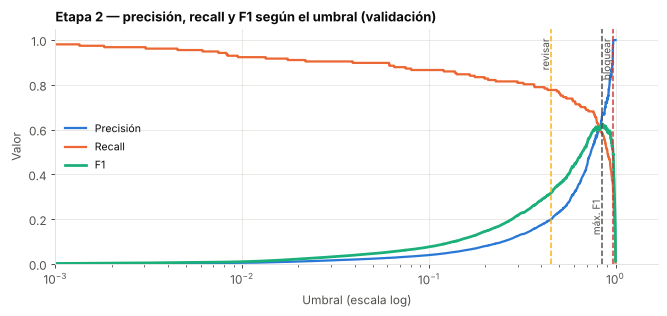

In [15]:
prec, rec, umb = precision_recall_curve(yva, p_va)
prec, rec = prec[:-1], rec[:-1]
f1s = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
UMBRAL = float(umb[np.nanargmax(f1s)])

umbral_bloqueo, precision_objetivo = None, None
for objetivo_p in PRECISIONES_BLOQUEO:
    ok = np.where(prec >= objetivo_p)[0]
    if len(ok):
        umbral_bloqueo, precision_objetivo = float(umb[ok[0]]), objetivo_p
        break
if umbral_bloqueo is None:
    umbral_bloqueo = UMBRAL
umbral_volumen = float(np.quantile(p_va, 1 - MAX_TASA_REVISION))   # tope de capacidad de los analistas


def umbral_revision_para(precision_minima):
    """El umbral más bajo con el que, de todo lo que se frena (score >= umbral: revisión + bloqueo), al menos
    `precision_minima` es fraude en validación; nunca frena más de MAX_TASA_REVISION del flujo."""
    ok = np.where(prec >= precision_minima)[0]
    u_precision = float(umb[ok[0]]) if len(ok) else umbral_bloqueo
    return min(max(u_precision, umbral_volumen), umbral_bloqueo * 0.999)


umbral_revision = umbral_revision_para(PRECISION_REVISION)
UMBRALES = {"umbral_bloqueo": round(umbral_bloqueo, 6), "umbral_revision": round(umbral_revision, 6),
            "precision_objetivo_bloqueo": precision_objetivo, "precision_minima_revision": PRECISION_REVISION,
            "max_tasa_revision": MAX_TASA_REVISION}
print(f"Umbral de clasificación (máximo F1 en validación): {UMBRAL:.4f}")
print("Política de la API:", UMBRALES)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(umb, prec, color=AZUL, lw=1.8, label="Precisión")
ax.plot(umb, rec, color=NARANJA, lw=1.8, label="Recall")
ax.plot(umb, f1s, color=SERIES[2], lw=2.2, label="F1")
for valor, texto, color, y_txt in [(UMBRAL, "máx. F1", TINTA_2, 0.30), (umbral_revision, "revisar", ESTADO["REVISAR"], 1.02),
                                   (umbral_bloqueo, "bloquear", ESTADO["BLOQUEAR"], 1.02)]:
    ax.axvline(valor, color=color, ls="--", lw=1.2)
    ax.text(valor, y_txt, texto + " ", rotation=90, ha="right", va="top", fontsize=8, color=TINTA_2)
ax.set_xscale("log")
ax.set_xlim(left=max(1e-3, float(umb.min())))
ax.set(xlabel="Umbral (escala log)", ylabel="Valor", ylim=(0, 1.05),
       title="Etapa 2 — precisión, recall y F1 según el umbral (validación)")
ax.legend(loc="center left", fontsize=8.5)
guardar(fig, "07_etapa2_umbral_validacion.png")

#### Sensibilidad de la regla de revisión (validación)

La tabla muestra qué pasaría en **validación** con distintas precisiones mínimas. Subir la precisión manda menos
transferencias legítimas a revisión, pero deja pasar más fraude. Si se quiere otro equilibrio, se cambia
`PRECISION_REVISION` en la celda de parámetros y se vuelve a ejecutar el notebook (prueba no se mira para elegirla).


In [16]:
# ¿Cuánto cambia la revisión según la precisión mínima exigida? (solo validación: aquí se elige la regla)
monto_va = df.loc[va, "monto_gs"].to_numpy()
filas = []
for p_min in (0.10, 0.15, 0.20, 0.25, 0.30):
    u = umbral_revision_para(p_min)
    ok = np.where(prec >= p_min)[0]
    u_precision = float(umb[ok[0]]) if len(ok) else umbral_bloqueo
    frena = p_va >= u
    rev = frena & (p_va < umbral_bloqueo)
    filas.append({
        "precisión mínima": f"{p_min:.0%}" + (" (elegida)" if p_min == PRECISION_REVISION else ""),
        "umbral_revision": round(u, 4),
        "% del flujo a revisión": round(rev.mean() * 100, 3),
        "legítimas a revisión": int((rev & (yva == 0)).sum()),
        "fraudes frenados": f"{int((frena & (yva == 1)).sum())} de {int(yva.sum())}",
        "% del monto de fraude frenado": round(monto_va[frena & (yva == 1)].sum() / monto_va[yva == 1].sum() * 100, 1),
        "1 fraude cada … revisiones": round(rev.sum() / max((rev & (yva == 1)).sum(), 1), 1),
        "limitado por el tope": bool(umbral_volumen > u_precision),
    })
sensibilidad_revision = pd.DataFrame(filas)
sensibilidad_revision.to_csv(REPORTES / "sensibilidad_revision.csv", index=False)
sensibilidad_revision


,precisión mínima,umbral_revision,% del flujo a revisión,legítimas a revisión,fraudes frenados,% del monto de fraude frenado,1 fraude cada … revisiones,limitado por el tope
0,10%,0.3565,0.277,695,126 de 157,90.5,11.1,True
1,15%,0.3565,0.277,695,126 de 157,90.5,11.1,True
2,20% (elegida),0.4530,0.199,482,122 de 157,90.1,8.4,False
3,25%,0.5290,0.147,345,117 de 157,86.0,6.8,False
4,30%,0.5802,0.117,264,116 de 157,85.6,5.5,False


### 3.3 Antes y después del ajuste (validación)

Ojo: el modelo ajustado se eligió **mirando validación**, por eso su métrica de validación es optimista. La medida
honesta es la de la etapa 3, en prueba.

In [17]:
prob_val["XGBoost ponderado ajustado"] = p_va
evaluar("2 · ajustado", "XGBoost ponderado ajustado", "validación", yva, p_va, UMBRAL)
antes_despues = pd.DataFrame([r for r in RESULTADOS if r["modelo"].startswith("XGBoost ponderado")]).set_index("modelo")[
    ["etapa", "umbral", "average_precision", "roc_auc", "f1", "precision", "recall", "tp", "fp", "fn"]]
antes_despues

XGBoost ponderado ajustado — validación (umbral 0.8485)
  average_precision=0.6323  roc_auc=0.9717  f1=0.6259  precision=0.6715  recall=0.586
              precision    recall  f1-score   support

    legítima     0.9998    0.9998    0.9998    275287
      fraude     0.6715    0.5860    0.6259       157

    accuracy                         0.9996    275444
   macro avg     0.8356    0.7929    0.8128    275444
weighted avg     0.9996    0.9996    0.9996    275444

confusion_matrix:
[[TN=275,242  FP=45]
 [FN=65  TP=92]]


,etapa,umbral,average_precision,roc_auc,f1,precision,recall,tp,fp,fn
modelo,,,,,,,,,,
XGBoost ponderado,1 · sin ajustes,0.5000,0.5353,0.9726,0.2166,0.1262,0.7643,120,831,37
XGBoost ponderado ajustado,2 · ajustado,0.8485,0.6323,0.9717,0.6259,0.6715,0.5860,92,45,65


## 4. Etapa 3 — Evaluación final en prueba (una sola vez)

El XGBoost ponderado ajustado, con sus hiperparámetros y su umbral elegidos en validación, se evalúa **una única vez**
en el conjunto de prueba (may – jun 2026), que no se usó para ninguna decisión. La regresión logística (*baseline*)
y el XGBoost ponderado sin ajustar no se evalúan en prueba: sirvieron para la comparación de la etapa 1.

In [18]:
p_te = modelo.predict_proba(Xte)[:, 1]
final = evaluar("3 · final", "XGBoost ponderado ajustado", "prueba", yte, p_te, UMBRAL)

# intervalo de confianza de la average precision en prueba (bootstrap estratificado)
rng = np.random.default_rng(SEED)
pos, neg = np.where(yte == 1)[0], np.where(yte == 0)[0]
boot = [average_precision_score(yte[i], p_te[i]) for i in
        (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(300))]
ic95 = [round(float(np.percentile(boot, 2.5)), 4), round(float(np.percentile(boot, 97.5)), 4)]
print(f"Average precision en prueba: {final['average_precision']} (IC 95 % bootstrap: {ic95[0]} – {ic95[1]})")

XGBoost ponderado ajustado — prueba (umbral 0.8485)
  average_precision=0.4727  roc_auc=0.9703  f1=0.466  precision=0.5926  recall=0.384
              precision    recall  f1-score   support

    legítima     0.9994    0.9998    0.9996    277528
      fraude     0.5926    0.3840    0.4660       250

    accuracy                         0.9992    277778
   macro avg     0.7960    0.6919    0.7328    277778
weighted avg     0.9991    0.9992    0.9991    277778

confusion_matrix:
[[TN=277,462  FP=66]
 [FN=154  TP=96]]


Average precision en prueba: 0.4727 (IC 95 % bootstrap: 0.4159 – 0.5269)


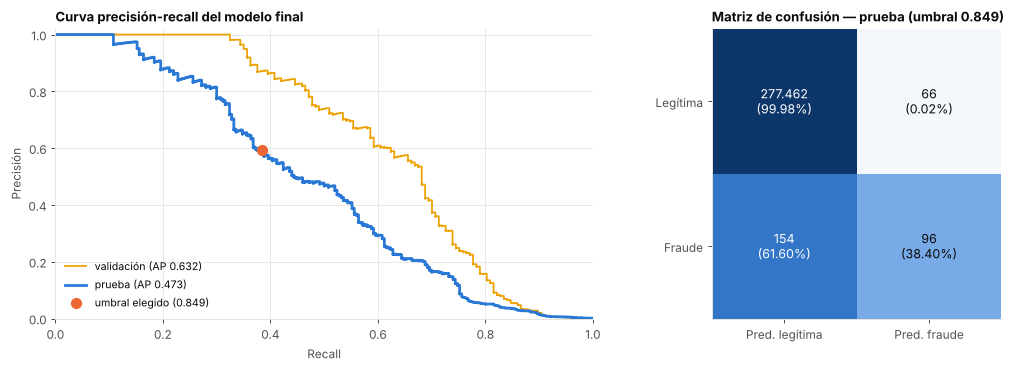

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axs[0]
for nombre_c, y_c, p_c, color in [("validación", yva, p_va, SERIES[3]), ("prueba", yte, p_te, AZUL)]:
    p, r, _ = precision_recall_curve(y_c, p_c)
    ax.step(r, p, where="post", color=color, lw=2.2 if nombre_c == "prueba" else 1.4,
            label=f"{nombre_c} (AP {average_precision_score(y_c, p_c):.3f})")
f_rec, f_prec = final["recall"], final["precision"]
ax.plot(f_rec, f_prec, "o", color=NARANJA, ms=8, zorder=3, label=f"umbral elegido ({UMBRAL:.3f})")
ax.set(xlabel="Recall", ylabel="Precisión", xlim=(0, 1), ylim=(0, 1.02),
       title="Curva precisión-recall del modelo final")
ax.legend(loc="lower left", fontsize=8.5)

ax = axs[1]
cm = np.array([[final["tn"], final["fp"]], [final["fn"], final["tp"]]])
pct = cm / cm.sum(axis=1, keepdims=True)
ax.imshow(pct, cmap=CMAP_AZUL, vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{gs(cm[i, j])}\n({pct[i, j]:.2%})", ha="center", va="center", fontsize=10,
                color="white" if pct[i, j] > 0.55 else TINTA)
ax.set_xticks([0, 1], ["Pred. legítima", "Pred. fraude"])
ax.set_yticks([0, 1], ["Legítima", "Fraude"])
ax.grid(False)
ax.set_title(f"Matriz de confusión — prueba (umbral {UMBRAL:.3f})")
guardar(fig, "08_etapa3_prueba_curva_y_matriz.png")

### 4.1 Política de la API en prueba e impacto en guaraníes

Se aplican los umbrales de 3 niveles elegidos en validación. Una transferencia fraudulenta se considera **detenida**
si se bloquea o se envía a revisión.

decision,APROBAR,REVISAR,BLOQUEAR
es_fraude,,,
Legítima,277017,502,9
Fraude,93,101,56


Fraudes detenidos: 157 de 250 (56 bloqueados, 101 a revisión)
Monto de fraude detenido: Gs. 173.984.990 de Gs. 221.643.387 (78.5%)
Legítimas bloqueadas: 9 · legítimas a revisión: 502 · precisión de los bloqueos: 0.8615


,recall,n
tipo_fraude,,
toma_de_cuenta,0.987179,78
rafaga_de_transferencias,0.500000,110
cuenta_mula,0.555556,45
camuflado,0.000000,17


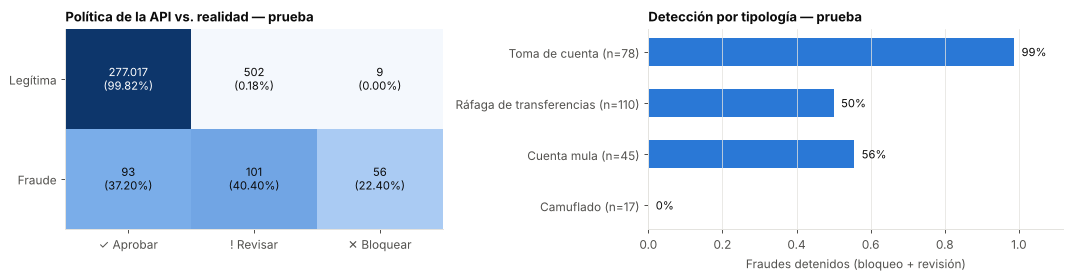

In [20]:
def decidir(p):
    return np.where(p >= UMBRALES["umbral_bloqueo"], "BLOQUEAR",
                    np.where(p >= UMBRALES["umbral_revision"], "REVISAR", "APROBAR"))


prueba = df[te].assign(score=p_te, decision=decidir(p_te))
detenido = prueba["decision"] != "APROBAR"
fr = prueba[prueba["es_fraude"] == 1]
tabla_dec = pd.crosstab(prueba["es_fraude"].map({0: "Legítima", 1: "Fraude"}), prueba["decision"]).reindex(
    index=["Legítima", "Fraude"], columns=["APROBAR", "REVISAR", "BLOQUEAR"], fill_value=0)
impacto = {
    "transacciones_test": int(len(prueba)), "fraudes_test": int(len(fr)),
    "decisiones": prueba["decision"].value_counts().to_dict(),
    "fraudes_bloqueados": int((fr["decision"] == "BLOQUEAR").sum()),
    "fraudes_a_revision": int((fr["decision"] == "REVISAR").sum()),
    "fraudes_aprobados": int((fr["decision"] == "APROBAR").sum()),
    "legitimas_bloqueadas": int(tabla_dec.loc["Legítima", "BLOQUEAR"]),
    "legitimas_a_revision": int(tabla_dec.loc["Legítima", "REVISAR"]),
    "monto_fraude_total_gs": int(fr["monto_gs"].sum()),
    "monto_fraude_detenido_gs": int(fr.loc[detenido[fr.index], "monto_gs"].sum()),
    "tasa_revision": round(float((prueba["decision"] == "REVISAR").mean()), 5),
    "precision_bloqueo": round(float(prueba.loc[prueba["decision"] == "BLOQUEAR", "es_fraude"].mean()), 4)
    if (prueba["decision"] == "BLOQUEAR").any() else None,
}
recall_tipo = (fr.assign(detenido=detenido[fr.index]).groupby("tipo_fraude")["detenido"]
               .agg(recall="mean", n="count").reindex(ORDEN_TIPOS))
impacto["recall_por_tipo"] = recall_tipo.round(3).to_dict(orient="index")
display(tabla_dec)
print(f"Fraudes detenidos: {impacto['fraudes_bloqueados'] + impacto['fraudes_a_revision']} de {impacto['fraudes_test']} "
      f"({impacto['fraudes_bloqueados']} bloqueados, {impacto['fraudes_a_revision']} a revisión)")
print(f"Monto de fraude detenido: Gs. {gs(impacto['monto_fraude_detenido_gs'])} de Gs. {gs(impacto['monto_fraude_total_gs'])} "
      f"({impacto['monto_fraude_detenido_gs'] / impacto['monto_fraude_total_gs']:.1%})")
print(f"Legítimas bloqueadas: {impacto['legitimas_bloqueadas']} · legítimas a revisión: {impacto['legitimas_a_revision']:,} "
      f"· precisión de los bloqueos: {impacto['precision_bloqueo']}")
display(recall_tipo)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axs[0]
pct = tabla_dec.div(tabla_dec.sum(axis=1), axis=0)
ax.imshow(pct.to_numpy(), cmap=CMAP_AZUL, vmin=0, vmax=1, aspect="auto")
for i in range(2):
    for j in range(3):
        ax.text(j, i, f"{gs(tabla_dec.iat[i, j])}\n({pct.iat[i, j]:.2%})", ha="center", va="center", fontsize=9,
                color="white" if pct.iat[i, j] > 0.55 else TINTA)
ax.set_xticks(range(3), ["✓ Aprobar", "! Revisar", "✕ Bloquear"])
ax.set_yticks(range(2), tabla_dec.index)
ax.grid(False)
ax.set_title("Política de la API vs. realidad — prueba")
ax = axs[1]
rt = recall_tipo.iloc[::-1]
ax.barh([f"{NOMBRE_TIPO[t]} (n={int(n)})" for t, n in zip(rt.index, rt["n"])], rt["recall"], color=AZUL, height=0.55)
for i, v in enumerate(rt["recall"]):
    ax.text(v + 0.02, i, f"{v:.0%}", va="center", fontsize=9)
ax.set(xlim=(0, 1.12), xlabel="Fraudes detenidos (bloqueo + revisión)", title="Detección por tipología — prueba")
ax.grid(axis="y", visible=False)
guardar(fig, "09_etapa3_politica_y_tipologias.png")

### 4.2 Importancia de las features, distribución de scores y sobreajuste

- **SHAP**: reparte cada predicción entre las features (valores de Shapley, aditivos en log-odds); se calcula con
  `pred_contribs=True` de XGBoost (TreeSHAP exacto). Se muestran dos vistas:
  - **Global** (todas las transferencias de prueba, 99,9 % legítimas): favorece a las señales **frecuentes**, porque
    mueven un poco el puntaje de muchísimas transferencias (por ejemplo, `destinatario_nuevo`).
  - **Sobre los fraudes**: qué explica que el modelo detecte un fraude; aquí pesan las señales **raras pero fuertes**
    (por ejemplo, `dispositivo_nuevo`).
  - `hora` y `es_nocturna` comparten la misma información (hora < 6 = madrugada): el árbol puede usar cualquiera
    de las dos, por eso conviene leerlas juntas como "información horaria".
- **Sobreajuste**: se compara la average precision del modelo final en entrenamiento, validación y prueba.

,global (todas),sobre fraudes
dispositivo_nuevo,0.4944,2.2916
n_tx_1h,0.9124,1.5476
hora,0.3881,1.2717
destinatario_nuevo,1.2182,1.2320
log_monto,0.4789,0.6994
log_ratio_monto_promedio,0.5303,0.5959
ciudad_distinta,0.1630,0.4599
es_fin_de_mes,0.1892,0.2209
log_antiguedad_origen,0.1642,0.1882
dia_semana,0.1092,0.0953


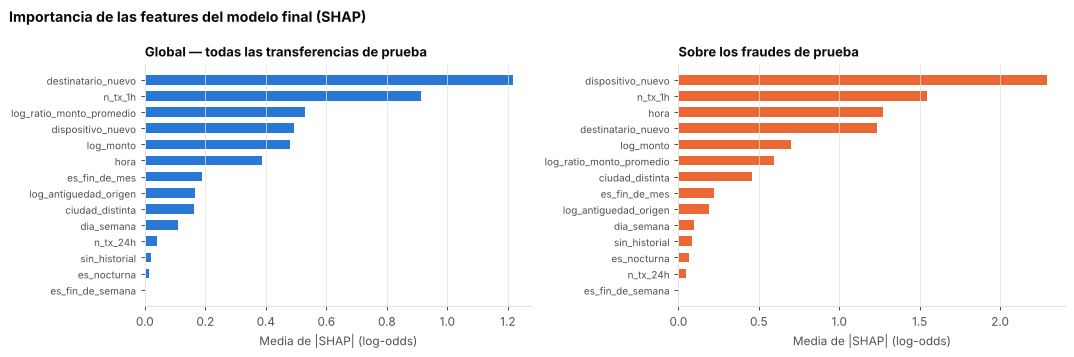

Average precision — entrenamiento / validación / prueba: {'pr_auc_train': 0.583, 'pr_auc_val': 0.6323, 'pr_auc_test': 0.4727, 'pr_auc_test_ic95': [0.4159, 0.5269]}


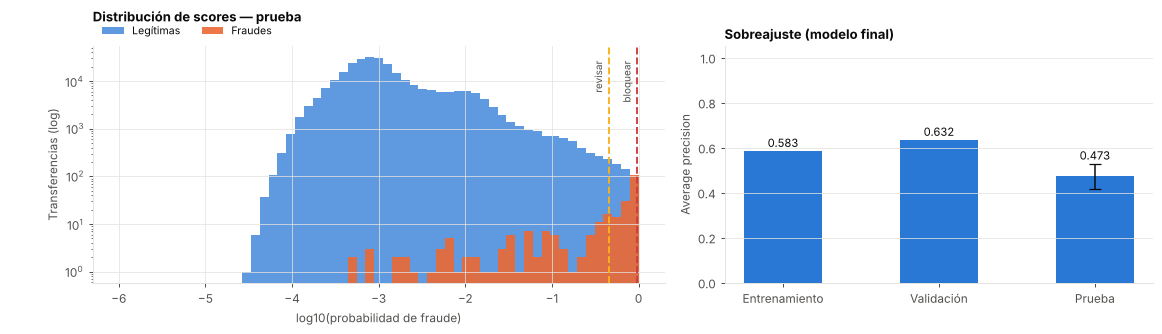

In [21]:
imp_final = shap_medio(modelo, Xte).sort_values(ascending=False)
imp_fraudes = shap_medio(modelo, Xte[yte == 1]).sort_values(ascending=False)
display(pd.DataFrame({"global (todas)": imp_final, "sobre fraudes": imp_fraudes}).round(4)
        .sort_values("sobre fraudes", ascending=False))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, serie, titulo in [(axs[0], imp_final, "Global — todas las transferencias de prueba"),
                          (axs[1], imp_fraudes, "Sobre los fraudes de prueba")]:
    s = serie.sort_values()
    ax.barh(s.index, s.values, color=AZUL if ax is axs[0] else NARANJA, height=0.6)
    ax.set(xlabel="Media de |SHAP| (log-odds)", title=titulo)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)
fig.suptitle("Importancia de las features del modelo final (SHAP)", x=0.01, ha="left", fontweight="bold")
guardar(fig, "10_etapa3_importancia_shap.png")

ap_tr, ap_va = average_precision_score(ytr, p_tr), average_precision_score(yva, p_va)
sobreajuste = {"pr_auc_train": round(float(ap_tr), 4), "pr_auc_val": round(float(ap_va), 4),
               "pr_auc_test": final["average_precision"], "pr_auc_test_ic95": ic95}
print("Average precision — entrenamiento / validación / prueba:", sobreajuste)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [0.05, 1.2, 0.9]})
axs[0].axis("off")

sc = np.log10(np.clip(p_te, 1e-6, 1))
bins = np.linspace(-6, 0, 60)
axs[1].hist(sc[yte == 0], bins=bins, color=AZUL, alpha=0.75, label="Legítimas")
axs[1].hist(sc[yte == 1], bins=bins, color=NARANJA, alpha=0.9, label="Fraudes")
axs[1].set_yscale("log")
for clave, texto, color in [("umbral_revision", "revisar", ESTADO["REVISAR"]), ("umbral_bloqueo", "bloquear", ESTADO["BLOQUEAR"])]:
    axs[1].axvline(np.log10(UMBRALES[clave]), color=color, ls="--", lw=1.5)
    axs[1].text(np.log10(UMBRALES[clave]) - 0.05, axs[1].get_ylim()[1] * 0.5, texto, rotation=90, ha="right",
                va="top", fontsize=8, color=TINTA_2)
axs[1].set(xlabel="log10(probabilidad de fraude)", ylabel="Transferencias (log)")
axs[1].set_title("Distribución de scores — prueba", loc="left", pad=20)
axs[1].legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=8.5)

vals = [ap_tr, ap_va, final["average_precision"]]
axs[2].bar(["Entrenamiento", "Validación", "Prueba"], vals, color=AZUL, width=0.5)
axs[2].errorbar(2, vals[2], yerr=[[vals[2] - ic95[0]], [ic95[1] - vals[2]]], color=TINTA, capsize=5, lw=1.2)
for i, v in enumerate(vals):
    axs[2].text(i, (ic95[1] if i == 2 else v) + 0.02, f"{v:.3f}", ha="center", fontsize=9)
axs[2].set(ylim=(0, 1.05), ylabel="Average precision", title="Sobreajuste (modelo final)")
axs[2].grid(axis="x", visible=False)
guardar(fig, "11_etapa3_scores_y_sobreajuste.png")

## 5. Exportar el modelo final y los resultados

| Archivo | Uso |
|---|---|
| `models/modelo_xgb.json` | modelo en formato nativo de XGBoost (no pickle): lo carga la API |
| `models/metadata.json` | features, hiperparámetros, umbrales de la política, métricas e impacto: lo leen la API y la interfaz |
| `models/verificacion_features.csv` | 50 transferencias de prueba con sus features calculadas: un test de la API comprueba que la API las calcula igual |
| `reports/comparacion_modelos.csv` | métricas de las tres etapas |
| `reports/optuna_historial.csv` | cada prueba de Optuna con sus hiperparámetros |
| `reports/classification_reports.txt` | `classification_report` y `confusion_matrix` de cada evaluación |
| `reports/RESULTADOS.md` | resumen de resultados |

In [22]:
booster = modelo.get_booster()
booster.save_model(MODELOS / "modelo_xgb.json")

# latencia de inferencia de una transferencia (lo que hará la API)
fila = Xte.iloc[[0]]
for _ in range(20):
    booster.predict(xgb.DMatrix(fila, feature_names=FEATURES))
t0 = time.perf_counter()
for _ in range(300):
    booster.predict(xgb.DMatrix(fila, feature_names=FEATURES))
latencia_ms = (time.perf_counter() - t0) / 300 * 1000

metadata = {
    "version": datetime.now(timezone.utc).strftime("%Y%m%d-%H%M"),
    "algoritmo": "XGBoost ponderado ajustado (Optuna + umbral)",
    "features": FEATURES,
    "hiperparametros": {k: (round(v, 5) if isinstance(v, float) else v) for k, v in mejores.items()},
    "ratio_legitimas_fraudes_train": round(float(ratio), 2),
    "pr_auc_validacion_optuna": round(float(estudio.best_value), 4),
    "umbral_clasificacion": round(UMBRAL, 6),
    "umbrales": UMBRALES,
    "metricas_test": {k: final[k] for k in ("average_precision", "roc_auc", "f1", "precision", "recall")}
                     | {"pr_auc": final["average_precision"]},
    "sobreajuste": sobreajuste,
    "latencia_inferencia_ms": round(latencia_ms, 3),
    "impacto_test": impacto,
    "importancia_shap": imp_final.round(4).to_dict(),
    "importancia_shap_fraudes": imp_fraudes.round(4).to_dict(),
    "periodos": {"train": "2025-07 a 2026-02", "validacion": "2026-03 a 2026-04", "test": "2026-05 a 2026-06"},
}
(MODELOS / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False, default=int), encoding="utf-8")

# 50 transferencias de prueba con sus features: la API debe calcularlas igual (tests/test_api.py)
muestra = df[te].sample(50, random_state=SEED)
pd.concat([muestra.drop(columns=["es_fraude", "tipo_fraude"]).reset_index(drop=True),
           construir_features(muestra).add_prefix("feat_").reset_index(drop=True)], axis=1).to_csv(
    MODELOS / "verificacion_features.csv", index=False)

comparacion = pd.DataFrame(RESULTADOS)
comparacion.to_csv(REPORTES / "comparacion_modelos.csv", index=False)
historial.to_csv(REPORTES / "optuna_historial.csv", index=False)
(REPORTES / "classification_reports.txt").write_text("\n".join(REPORTES_TXT), encoding="utf-8")
print(f"Latencia de inferencia: {latencia_ms:.2f} ms por transferencia")
print("Exportado en", MODELOS, "y", REPORTES)
comparacion

Latencia de inferencia: 1.53 ms por transferencia
Exportado en /home/claude/detector-sip/models y /home/claude/detector-sip/reports


,etapa,modelo,conjunto,umbral,average_precision,roc_auc,f1,precision,recall,tp,fp,fn,tn
0,1 · sin ajustes,Regresión logística,validación,0.5000,0.1187,0.9614,0.0249,0.0126,0.8726,137,10729,20,264558
1,1 · sin ajustes,XGBoost ponderado,validación,0.5000,0.5353,0.9726,0.2166,0.1262,0.7643,120,831,37,274456
2,2 · ajustado,XGBoost ponderado ajustado,validación,0.8485,0.6323,0.9717,0.6259,0.6715,0.5860,92,45,65,275242
3,3 · final,XGBoost ponderado ajustado,prueba,0.8485,0.4727,0.9703,0.4660,0.5926,0.3840,96,66,154,277462


In [23]:
imp = impacto
lineas = [
    "# Resultados (generado por notebooks/02_entrenamiento.ipynb)", "",
    f"Modelo final (API): **{metadata['algoritmo']}** · versión {metadata['version']}", "",
    "## Partición temporal", "", resumen_particion.to_markdown(), "",
    "## Etapa 1 — primera prueba en validación (sin ajustes, umbral 0,5)", "",
    comparacion[comparacion["etapa"].str.startswith("1")].drop(columns="etapa").to_markdown(index=False), "",
    "## Etapa 2 — ajuste del XGBoost ponderado (validación)", "",
    f"Hiperparámetros elegidos por Optuna ({N_PRUEBAS} pruebas, average precision en validación):", "",
    pd.Series(metadata["hiperparametros"]).to_frame("valor").to_markdown(), "",
    f"Umbral de clasificación (máximo F1 en validación): **{UMBRAL:.4f}** · política de la API: bloquear si score ≥ "
    f"{UMBRALES['umbral_bloqueo']:.4f}, revisar si score ≥ {UMBRALES['umbral_revision']:.4f}", "",
    f"Regla de revisión: de todo lo que se frena (revisión + bloqueo), al menos el {PRECISION_REVISION:.0%} es fraude en "
    f"validación, sin frenar más del {MAX_TASA_REVISION:.1%} del flujo. Sensibilidad de la regla (validación):", "",
    sensibilidad_revision.to_markdown(index=False), "",
    antes_despues.to_markdown(), "",
    "## Etapa 3 — evaluación final en prueba (una sola vez)", "",
    comparacion[comparacion["etapa"].str.startswith("3")].drop(columns="etapa").to_markdown(index=False), "",
    f"Average precision en prueba: **{final['average_precision']}** (IC 95 % bootstrap: {ic95[0]} – {ic95[1]}) · "
    f"entrenamiento {sobreajuste['pr_auc_train']} · validación {sobreajuste['pr_auc_val']}", "",
    "### Política de la API en prueba", "", tabla_dec.to_markdown(), "",
    f"- Fraudes detenidos: {imp['fraudes_bloqueados'] + imp['fraudes_a_revision']} de {imp['fraudes_test']} "
    f"({imp['fraudes_bloqueados']} bloqueados, {imp['fraudes_a_revision']} a revisión)",
    f"- Monto de fraude detenido: Gs. {gs(imp['monto_fraude_detenido_gs'])} de Gs. {gs(imp['monto_fraude_total_gs'])} "
    f"({imp['monto_fraude_detenido_gs'] / imp['monto_fraude_total_gs']:.1%})",
    f"- Legítimas bloqueadas: {imp['legitimas_bloqueadas']} · legítimas a revisión: {imp['legitimas_a_revision']} "
    f"({imp['tasa_revision']:.2%} del flujo a revisión) · precisión de los bloqueos: {imp['precision_bloqueo']}",
    f"- Latencia de inferencia: {metadata['latencia_inferencia_ms']} ms por transferencia", "",
    "### Detección por tipología (prueba)", "", recall_tipo.round(3).to_markdown(), "",
    "### Importancia de las features (media de |SHAP|, prueba)", "",
    pd.DataFrame({"global": imp_final, "sobre_fraudes": imp_fraudes}).round(4)
    .sort_values("sobre_fraudes", ascending=False).to_markdown(), "",
]
(REPORTES / "RESULTADOS.md").write_text("\n".join(lineas), encoding="utf-8")
print("reports/RESULTADOS.md listo")

reports/RESULTADOS.md listo


## 6. Limitaciones

- **Datos sintéticos:** las métricas miden qué tan bien el modelo aprende los patrones definidos en
  `generar_datos.py`; no estiman el rendimiento con datos reales de un banco.
- **Pocos fraudes por conjunto** (unos cientos en validación y en prueba): las métricas tienen incertidumbre (ver el
  IC 95 %), y más aún por tipología.
- **Validación optimista:** el modelo ajustado se eligió con validación; la cifra honesta es la de prueba.
- **El camuflado** se parece por diseño a las transferencias legítimas (estafas en las que la víctima autoriza el pago
  y cuentas de contactos habituales comprometidas): es la tipología que menos se detecta y, con pocas transferencias
  en prueba, su tasa de detección es muy inestable. Haría falta información que no está en las features (por ejemplo, actividad de la cuenta destino).
- **El RiskScore no es una probabilidad calibrada**: `scale_pos_weight` desplaza las probabilidades; sirve para ordenar
  el riesgo.